# 01 · Data Profiling
*Shape, hierarchy, data quality, and the structure the analysis will exploit.*

> ⚠️ **Synthetic data.** These notebooks run on the generated M5-shaped sample so every
> cell is reproducible out of the box. The *mechanics* are real; the *numbers are not a
> business finding*. Set `data_source.mode: real` in `config.yaml`, drop the Kaggle M5
> files into `data/raw/`, run `make all`, and re-run — every cell applies unchanged.

In [1]:
import os
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')  # run from project root whether launched here or above
import duckdb, pandas as pd, numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.grid': True, 'grid.alpha': .3, 'axes.spines.top': False, 'axes.spines.right': False})
con = duckdb.connect('data/processed/rci.duckdb', read_only=True)
EXT = 'dashboard/extracts'
pd.set_option('display.width', 150); pd.set_option('display.max_columns', 20)

## Dataset shape & hierarchy

In [2]:
cal = pd.read_csv('data/raw/calendar.csv', keep_default_na=False)
sal = pd.read_csv('data/raw/sales_train_evaluation.csv')
pri = pd.read_csv('data/raw/sell_prices.csv')
dcols = [c for c in sal.columns if c.startswith('d_')]
print(f'sales : {len(sal):,} series x {len(dcols)} days')
print(f'prices: {len(pri):,} weekly rows')
print(f'dates : {cal.date.min()} -> {cal.date.max()} ({len(cal)} days)')
print()
print('hierarchy:', sal.state_id.nunique(), 'states,', sal.store_id.nunique(),
      'stores,', sal.cat_id.nunique(), 'categories,', sal.dept_id.nunique(),
      'departments,', sal.item_id.nunique(), 'items')

sales : 2,100 series x 730 days
prices: 220,500 weekly rows
dates : 2013-01-01 -> 2014-12-31 (730 days)

hierarchy: 3 states, 10 stores, 3 categories, 7 departments, 210 items


## Intermittency & data quality
Retail demand is *intermittent* — many item-days sell zero units. Quantifying it up
front tells us medians and zero-inflation matter more than means.

In [3]:
vals = sal[dcols].to_numpy()
print(f'zero-unit share : {(vals == 0).mean():.1%}')
print(f'median daily units (nonzero): {np.median(vals[vals>0]):.0f}')
print(f'price coverage  : {con.execute("SELECT 100.0*avg((sell_price IS NOT NULL)::int) FROM fact_daily_sales").fetchone()[0]:.2f}%')
print(f'negative units  : {(vals < 0).sum()}   negative prices: {(pri.sell_price < 0).sum()}')

zero-unit share : 28.6%
median daily units (nonzero): 2
price coverage  : 100.00%
negative units  : 0   negative prices: 0


## Sales value by category over time

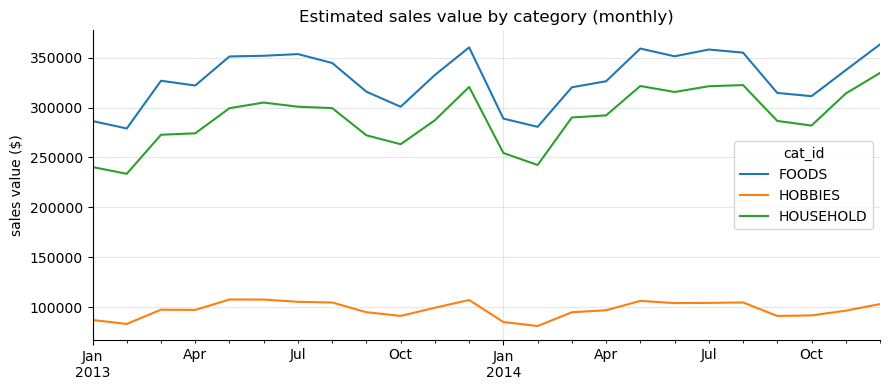

In [4]:
q = con.execute('''SELECT date_trunc('month', date_key) m, cat_id,
                          SUM(sales_value) v FROM mart_daily GROUP BY 1,2''').df()
piv = q.pivot(index='m', columns='cat_id', values='v')
ax = piv.plot(); ax.set_title('Estimated sales value by category (monthly)')
ax.set_ylabel('sales value ($)'); ax.set_xlabel(''); plt.tight_layout(); plt.show()

## Events & SNAP
The calendar carries holidays and state SNAP-benefit days — both are demand levers we
test in notebook 02.

In [5]:
print('distinct events:', sorted(cal.loc[cal.event_name_1!='','event_name_1'].unique()))
print('SNAP days  CA/TX/WI:', int(cal.snap_CA.sum()), int(cal.snap_TX.sum()), int(cal.snap_WI.sum()))

distinct events: ['Christmas', 'Easter', 'Halloween', 'IndependenceDay', 'LaborDay', 'MothersDay', 'NewYear', 'NewYearEve', 'SuperBowl', 'Thanksgiving', 'ValentinesDay']
SNAP days  CA/TX/WI: 240 216 264


### Takeaways
- Clean, continuous daily panel across the full M5 hierarchy (state → store → category → dept → item).
- Demand is intermittent (large zero share) → use robust/aggregate views, not raw daily means.
- Events, SNAP, and weekly prices are all present → the diagnostic levers exist in the data.